# Cleaned LiDAR roof metrics for UDU tracts

This notebook processes the 300 census tracts with observed UDUs using the writer-free USGS EPT workflow. It applies the LARIAC-height ceiling, curvature filter, and iterative multi-plane RANSAC, while preserving raw and cleaned measurements side by side. Run with the project's LiDAR/PDAL environment.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import importlib
import sys
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from tqdm.auto import tqdm

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'scripts/run_roof_lidar_ept_cleaned.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'scripts/run_roof_lidar_ept_cleaned.py').exists():
    raise FileNotFoundError('Could not find the HiddenHousing repository root.')
sys.path.insert(0, str(ROOT / 'scripts'))

import run_roof_lidar_tile
import run_roof_lidar_ept
import run_roof_lidar_ept_cleaned
import run_lacity_roof_tiles

# Reload in dependency order so an exploratory kernel cannot retain stale code.
importlib.reload(run_roof_lidar_tile)
importlib.reload(run_roof_lidar_ept)
importlib.reload(run_roof_lidar_ept_cleaned)
importlib.reload(run_lacity_roof_tiles)

from run_lacity_roof_tiles import GRID_PATH, grid_tile_extent
from run_roof_lidar_ept_cleaned import compare_roofs_ept_cleaned
from run_roof_lidar_tile import LARIAC_DIR, PARCEL_PATH, load_tile_structures

UDU_CSV = Path('/Users/adamswietek/Documents/NDSC_HiddenHousing/data/01_source/ct_udu.csv')
TRACT_ZIP = ROOT / 'data/01_raw/census/cb_2020_06_tract_500k.zip'
TRACT_URL = 'https://www2.census.gov/geo/tiger/GENZ2020/shp/cb_2020_06_tract_500k.zip'
if not TRACT_ZIP.exists():
    TRACT_ZIP.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(TRACT_URL, TRACT_ZIP)

udu = pd.read_csv(UDU_CSV, dtype={'geoid20': 'string'})
udu = udu.loc[udu['join_count'].fillna(0).gt(0)].copy()
udu['GEOID'] = udu['geoid20'].str.zfill(11)
tracts = gpd.read_file(f'zip://{TRACT_ZIP}')
udu_tracts = tracts.loc[tracts['GEOID'].isin(udu['GEOID'])].merge(
    udu[['GEOID', 'join_count']], on='GEOID', how='inner', validate='one_to_one',
)
grid = gpd.read_file(GRID_PATH, layer='tiles', engine='pyogrio')
positive_udu_tracts = udu_tracts.to_crs(grid.crs)[['GEOID', 'join_count', 'geometry']]
tile_tract_pairs = gpd.sjoin(
    grid[['tile_id', 'geometry']],
    positive_udu_tracts,
    how='inner', predicate='intersects',
)
eligible_tile_ids = sorted(tile_tract_pairs['tile_id'].unique())

print(f'{len(udu):,} positive-UDU tracts; {udu.join_count.sum():,.0f} UDU observations')
print(f'{len(eligible_tile_ids):,} intersecting LA City tiles')

300 positive-UDU tracts; 437 UDU observations
559 intersecting LA City tiles


## Processing coverage

Blue polygons are the 300 positive-UDU tracts; red outlines are the intersecting 1 km processing tiles.

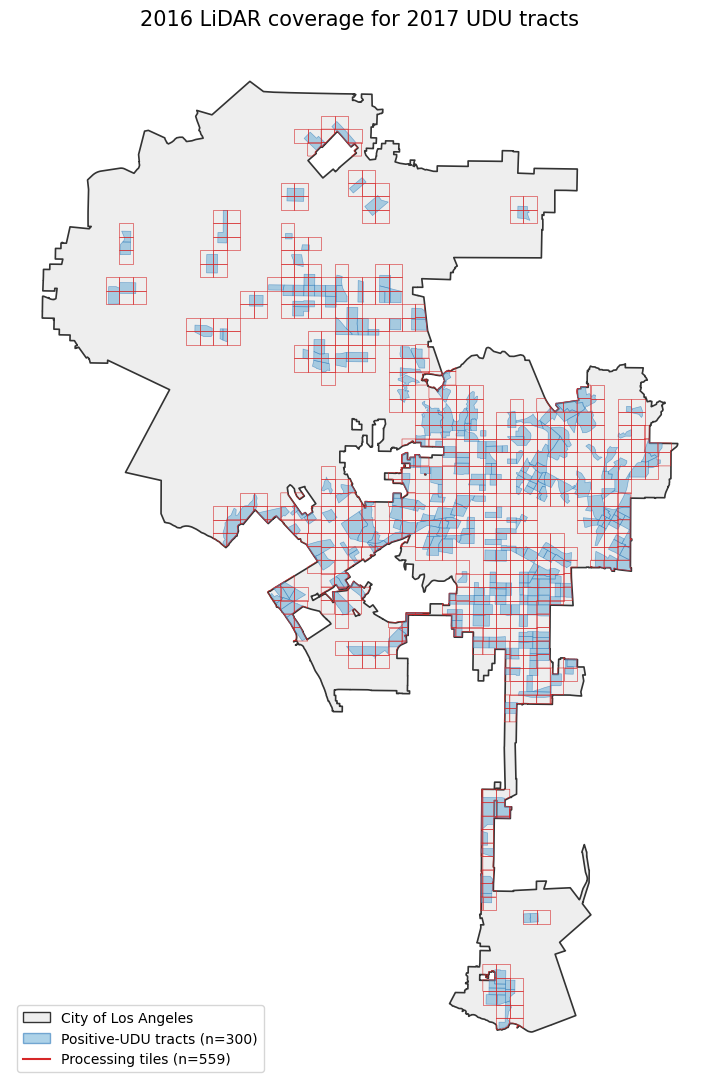

In [2]:
LA_CITY_PATH = ROOT / 'data/02_interm/boundaries/lacity_boundary.geojson'
la_city = gpd.read_file(LA_CITY_PATH).to_crs(grid.crs)
associated_tiles = grid.loc[grid['tile_id'].isin(eligible_tile_ids)].copy()

fig, ax = plt.subplots(figsize=(11, 11))
la_city.plot(ax=ax, facecolor='#eeeeee', edgecolor='#333333', linewidth=1.2, zorder=1)
positive_udu_tracts.plot(
    ax=ax, facecolor='#6baed6', edgecolor='#2171b5',
    linewidth=0.45, alpha=0.55, zorder=2,
)
associated_tiles.boundary.plot(
    ax=ax, color='#d62728', linewidth=0.45, alpha=0.9, zorder=3,
)
ax.legend(handles=[
    Patch(facecolor='#eeeeee', edgecolor='#333333', label='City of Los Angeles'),
    Patch(facecolor='#6baed6', edgecolor='#2171b5', alpha=0.55,
          label=f'Positive-UDU tracts (n={len(positive_udu_tracts):,})'),
    Line2D([0], [0], color='#d62728', linewidth=1.5,
           label=f'Processing tiles (n={len(associated_tiles):,})'),
], loc='lower left', frameon=True)
ax.set_title('2016 LiDAR coverage for 2017 UDU tracts', fontsize=15)
ax.set_aspect('equal')
ax.set_axis_off()
plt.tight_layout()
plt.show()

## Production run: all 300 UDU tracts

This restartable cell processes all 559 intersecting tiles. Each completed tile is cached as a raw-versus-cleaned Parquet. At completion it writes a full audit table and a compact derivative containing the cleaned median slope, LARIAC height, and roof type. The provisional classification uses a 5 degree cleaned-median cutoff and requires at least 100 cleaned points.

In [3]:
CLEANED_OUTPUT_DIR = ROOT / 'data/03_processed/roof_slope_udu_ept_cleaned'
CLEANED_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FULL_OUTPUT_PATH = CLEANED_OUTPUT_DIR / 'udu_300_tracts_roof_metrics_full.parquet'
DERIVATIVE_OUTPUT_PATH = CLEANED_OUTPUT_DIR / 'udu_300_tracts_roof_classification.parquet'
MIN_CLEAN_POINTS = 100
FLAT_MEDIAN_SLOPE_DEG = 5.0

tile_tables = []
progress = tqdm(
    eligible_tile_ids, total=len(eligible_tile_ids),
    desc='Cleaned UDU roof tiles', unit='tile', dynamic_ncols=True,
)
for tile_id in progress:
    progress.set_postfix_str(tile_id, refresh=True)
    output_path = CLEANED_OUTPUT_DIR / f'{tile_id}_raw_vs_cleaned.parquet'
    if output_path.exists():
        tile_table = pd.read_parquet(output_path)
        required_columns = {
            'raw_slope_median_deg', 'clean_slope_median_deg',
            'clean_n_roof_points', 'clean_roof_height_p10_m',
            'clean_roof_height_p95_m', 'clean_roof_relief_p90_m',
            'lariac_height_m', 'clean_status', 'GEOID', 'source_tile',
        }
        if required_columns.issubset(tile_table.columns):
            tile_tables.append(tile_table)
            progress.set_postfix(tile=tile_id, rows=len(tile_table), cached=True)
            continue

    tile = grid.loc[grid['tile_id'].eq(tile_id)].iloc[0]
    structures = load_tile_structures(
        grid_tile_extent(tile),
        year=2017, lariac_dir=LARIAC_DIR, parcel_path=PARCEL_PATH,
        core_geometry=tile.geometry, core_crs=grid.crs,
    )
    tile_tracts = positive_udu_tracts.loc[
        positive_udu_tracts.geometry.intersects(tile.geometry)
    ]
    structure_points = structures[['BLD_ID', 'geometry']].copy()
    structure_points.geometry = structure_points.geometry.representative_point()
    tract_matches = gpd.sjoin(
        structure_points, tile_tracts[['GEOID', 'geometry']],
        how='inner', predicate='intersects',
    ).sort_values(['BLD_ID', 'GEOID']).drop_duplicates('BLD_ID')
    tract_lookup = tract_matches[['BLD_ID', 'GEOID']]
    tract_structures = structures.loc[
        structures['BLD_ID'].isin(tract_lookup['BLD_ID'])
    ].copy()
    if tract_structures.empty:
        progress.set_postfix(tile=tile_id, rows=0)
        continue

    started = time.perf_counter()
    tile_table = compare_roofs_ept_cleaned(
        tract_structures,
        resolution=0.5, query_buffer_m=10.0, show_progress=False,
    )
    elapsed = time.perf_counter() - started
    diagnostics = tile_table.attrs['ept_diagnostics']
    tile_table = tile_table.merge(tract_lookup, on='BLD_ID', how='left')
    tile_table.insert(0, 'source_tile', tile_id)
    temporary_path = output_path.with_suffix('.tmp.parquet')
    tile_table.to_parquet(temporary_path, index=False)
    temporary_path.replace(output_path)
    tile_tables.append(tile_table)
    progress.set_postfix(
        tile=tile_id, rows=len(tile_table),
        points=f"{diagnostics['streamed_points']:,}", seconds=f'{elapsed:.1f}',
        refresh=True,
    )

if not tile_tables:
    raise ValueError('No structures were processed for the UDU tracts.')
full_roof_table = pd.concat(tile_tables, ignore_index=True)
full_roof_table = full_roof_table.sort_values(
    ['GEOID', 'source_tile', 'AIN', 'BLD_ID'], na_position='last'
).reset_index(drop=True)
if full_roof_table['BLD_ID'].duplicated().any():
    duplicates = full_roof_table.loc[
        full_roof_table['BLD_ID'].duplicated(), 'BLD_ID'
    ]
    raise ValueError(f'Duplicate buildings across tiles: {duplicates.head().tolist()}')
full_temporary = FULL_OUTPUT_PATH.with_suffix('.tmp.parquet')
full_roof_table.to_parquet(full_temporary, index=False)
full_temporary.replace(FULL_OUTPUT_PATH)

enough_clean_points = (
    full_roof_table['clean_status'].eq('ok')
    & full_roof_table['clean_n_roof_points'].ge(MIN_CLEAN_POINTS)
    & full_roof_table['clean_slope_median_deg'].notna()
)
roof_type_clean = np.select(
    [
        ~enough_clean_points,
        full_roof_table['clean_slope_median_deg'].le(FLAT_MEDIAN_SLOPE_DEG),
    ],
    ['insufficient_points', 'flat'],
    default='pitched',
)
roof_derivative = full_roof_table[[
    'AIN', 'BLD_ID', 'clean_slope_median_deg', 'lariac_height_m',
]].rename(columns={'clean_slope_median_deg': 'median_slope_clean_deg'})
roof_derivative['roof_type_clean'] = roof_type_clean
derivative_temporary = DERIVATIVE_OUTPUT_PATH.with_suffix('.tmp.parquet')
roof_derivative.to_parquet(derivative_temporary, index=False)
derivative_temporary.replace(DERIVATIVE_OUTPUT_PATH)

print(f'Saved {len(full_roof_table):,} full rows to {FULL_OUTPUT_PATH}')
print(f'Saved {len(roof_derivative):,} derivative rows to {DERIVATIVE_OUTPUT_PATH}')
display(full_roof_table['clean_status'].value_counts(dropna=False).to_frame('n_structures'))
display(roof_derivative['roof_type_clean'].value_counts(dropna=False).to_frame('n_structures'))
display(roof_derivative.head())

Cleaned UDU roof tiles:   0%|          | 0/559 [00:00<?, ?tile/s]

Saved 281,365 full rows to /Users/adamswietek/Documents/PostDoc/HiddenHousing/data/03_processed/roof_slope_udu_ept_cleaned/udu_300_tracts_roof_metrics_full.parquet
Saved 281,365 derivative rows to /Users/adamswietek/Documents/PostDoc/HiddenHousing/data/03_processed/roof_slope_udu_ept_cleaned/udu_300_tracts_roof_classification.parquet


,n_structures
clean_status,
ok,253284
no_planar_cluster,25314
no_raw_points,2767


,n_structures
roof_type_clean,
pitched,145638
insufficient_points,80301
flat,55426


,AIN,BLD_ID,median_slope_clean_deg,lariac_height_m,roof_type_clean
0,2565017900,201700229930,1.454613,11.588496,flat
1,2565017900,475375914379,2.135838,3.688080,flat
2,2565017900,475530914656,1.191733,4.657344,flat
3,2565017900,475587914475,2.809513,3.264408,flat
4,2565017900,475594914535,22.993292,6.251448,pitched


## First-tile validation

The saved `la_005_054` comparison is used to inspect how canopy cleaning changes roof relief while preserving normal roofs.

,value
structures,947.000000
cleaned successfully,873.000000
no planar cluster,65.000000
no raw points,9.000000
raw relief > 10 m,24.000000
clean relief > 10 m,0.000000
median relief correction (m),0.030967
median retained point share,0.933962


,AIN,BLD_ID,lariac_height_m,raw_roof_height_p95_m,clean_roof_height_p95_m,raw_roof_relief_p90_m,clean_roof_relief_p90_m,relief_correction_m,clean_retained_share,clean_plane_count,clean_status
851,2139003021,2014121101530000,4.943856,23.828213,3.860540,20.867980,1.101885,19.766095,0.361702,1,ok
550,2139017006,377193891798,5.041392,22.179507,4.267115,18.971078,1.047557,17.923521,0.346939,1,ok
411,2139020014,377322891218,5.748528,21.311507,3.547635,18.053885,0.523247,17.530638,0.289157,1,ok
496,2139003021,377751891017,4.885944,21.260425,3.717191,17.996467,0.473176,17.523290,0.314136,1,ok
342,2024033023,376748893864,4.285488,19.823690,3.410167,17.087578,0.707896,16.379682,0.723751,2,ok
711,2024036009,375951893840,4.163568,18.684363,3.231759,15.982574,0.733507,15.249067,0.330986,1,ok
882,2139020024,201700287156,5.199888,18.160387,4.033003,14.662110,0.707713,13.954397,0.337095,1,ok
363,2139020024,377688891603,4.529328,20.552331,7.045767,17.597406,4.301457,13.295949,0.274232,2,ok
592,2139009014,376039893359,4.568952,16.439692,3.630301,13.613846,0.873419,12.740427,0.690705,2,ok
166,2024006015,377918894020,5.358384,16.323206,4.599619,13.024964,1.339335,11.685630,0.815152,3,ok


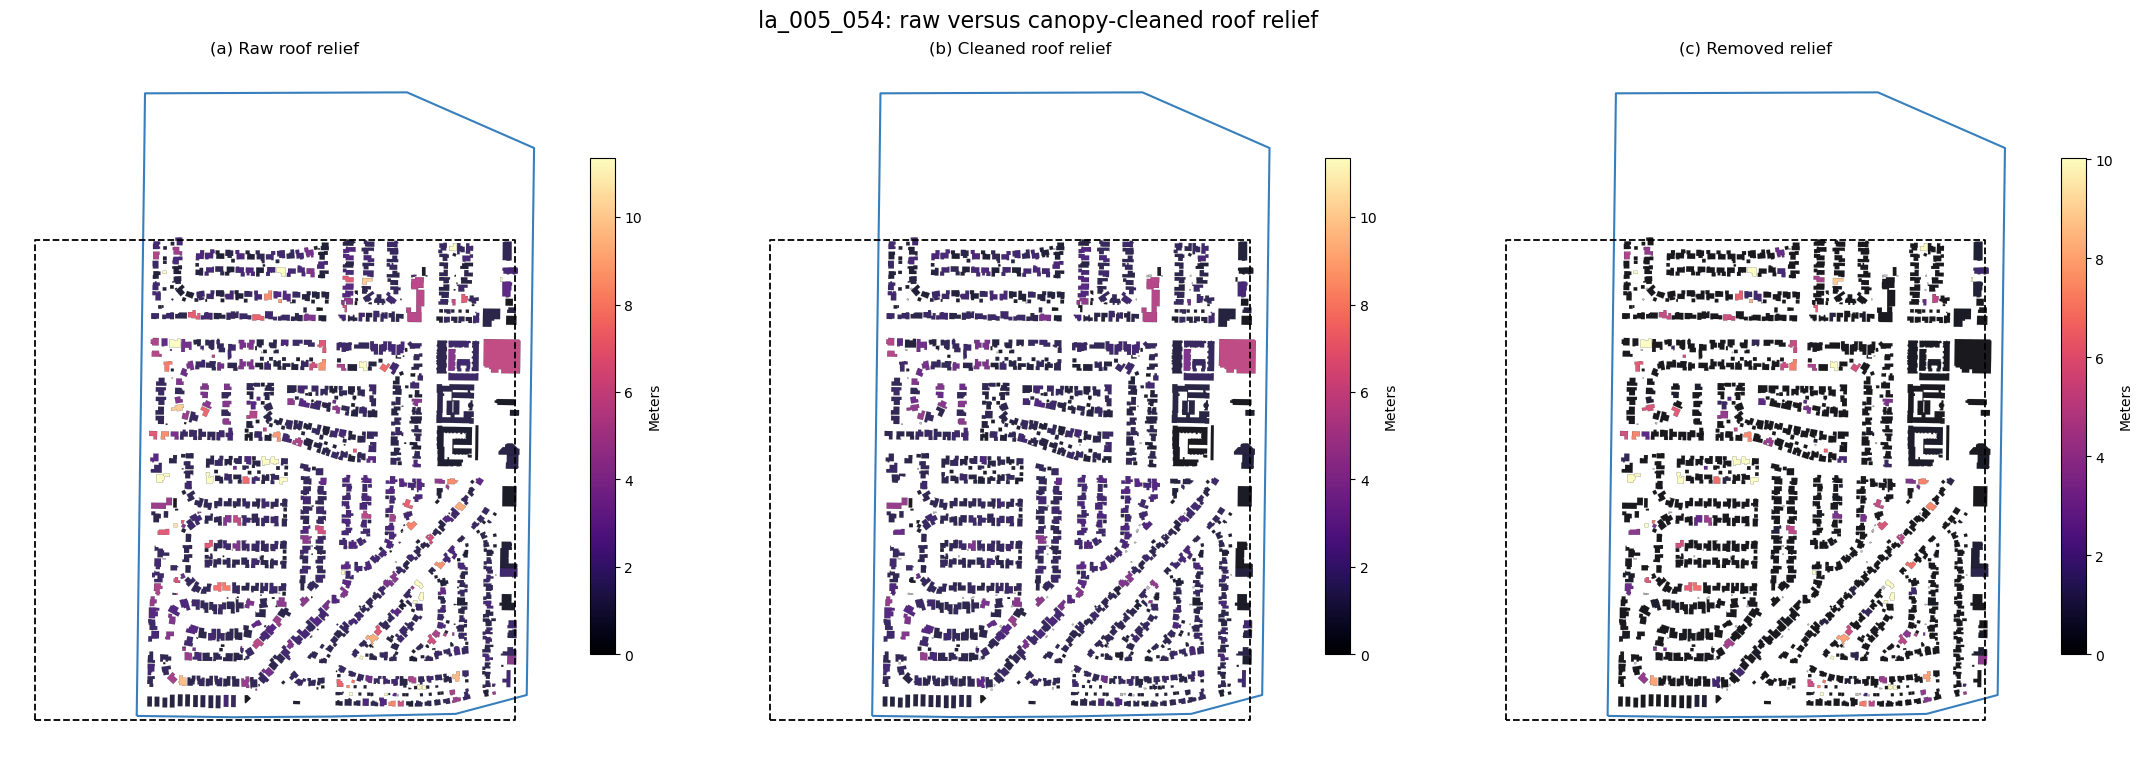

In [4]:
COMPARISON_PATH = (
    ROOT / 'data/03_processed/roof_slope_udu_ept_cleaned'
    / 'la_005_054_raw_vs_cleaned.parquet'
)
comparison = pd.read_parquet(COMPARISON_PATH)
comparison_ok = comparison['clean_status'].eq('ok')
summary = pd.Series({
    'structures': len(comparison),
    'cleaned successfully': int(comparison_ok.sum()),
    'no planar cluster': int(comparison['clean_status'].eq('no_planar_cluster').sum()),
    'no raw points': int(comparison['clean_status'].eq('no_raw_points').sum()),
    'raw relief > 10 m': int(comparison['raw_roof_relief_p90_m'].gt(10).sum()),
    'clean relief > 10 m': int(comparison['clean_roof_relief_p90_m'].gt(10).sum()),
    'median relief correction (m)': comparison['relief_correction_m'].median(),
    'median retained point share': comparison.loc[comparison_ok, 'clean_retained_share'].median(),
}, name='value').to_frame()
display(summary)
display(comparison.nlargest(20, 'relief_correction_m')[[
    'AIN', 'BLD_ID', 'lariac_height_m',
    'raw_roof_height_p95_m', 'clean_roof_height_p95_m',
    'raw_roof_relief_p90_m', 'clean_roof_relief_p90_m',
    'relief_correction_m', 'clean_retained_share',
    'clean_plane_count', 'clean_status',
]])

comparison_tile_id = comparison['source_tile'].iloc[0]
comparison_tile = grid.loc[grid['tile_id'].eq(comparison_tile_id)].iloc[0]
comparison_footprints = load_tile_structures(
    grid_tile_extent(comparison_tile),
    year=2017, lariac_dir=LARIAC_DIR, parcel_path=PARCEL_PATH,
    core_geometry=comparison_tile.geometry, core_crs=grid.crs,
)[['BLD_ID', 'geometry']]
comparison_map = comparison_footprints.merge(
    comparison, on='BLD_ID', how='inner', validate='one_to_one',
)
comparison_map = gpd.GeoDataFrame(comparison_map, crs=comparison_footprints.crs)
comparison_tracts = positive_udu_tracts.loc[
    positive_udu_tracts['GEOID'].isin(comparison['GEOID'].dropna())
].to_crs(comparison_map.crs)
comparison_core = gpd.GeoSeries(
    [comparison_tile.geometry], crs=grid.crs,
).to_crs(comparison_map.crs)

relief_vmax = comparison['raw_roof_relief_p90_m'].quantile(0.98)
correction_vmax = comparison['relief_correction_m'].clip(lower=0).quantile(0.98)
panels = [
    ('raw_roof_relief_p90_m', '(a) Raw roof relief', relief_vmax),
    ('clean_roof_relief_p90_m', '(b) Cleaned roof relief', relief_vmax),
    ('relief_correction_m', '(c) Removed relief', correction_vmax),
]
fig, axes = plt.subplots(1, 3, figsize=(22, 7.5), constrained_layout=True)
for ax, (field, title, vmax) in zip(axes, panels):
    comparison_map.plot(
        ax=ax, column=field, cmap='magma', vmin=0, vmax=max(vmax, 0.1),
        legend=True, legend_kwds={'label': 'Meters', 'shrink': 0.72},
        missing_kwds={'color': '#bdbdbd'},
        edgecolor='black', linewidth=0.12, alpha=0.9, zorder=2,
    )
    comparison_tracts.boundary.plot(
        ax=ax, color='#2171b5', linewidth=1.5, alpha=0.9, zorder=3,
    )
    comparison_core.boundary.plot(
        ax=ax, color='black', linewidth=1.3, linestyle='--', zorder=4,
    )
    ax.set_title(title)
    ax.set_aspect('equal')
    ax.set_axis_off()
fig.suptitle(f'{comparison_tile_id}: raw versus canopy-cleaned roof relief', fontsize=16)
plt.show()

## Cleaned eave height and median slope

The eave proxy is the cleaned p10 height above ground. The slope panel shows the median point-normal slope from retained planar roof points. Gray buildings have no accepted planar cluster.

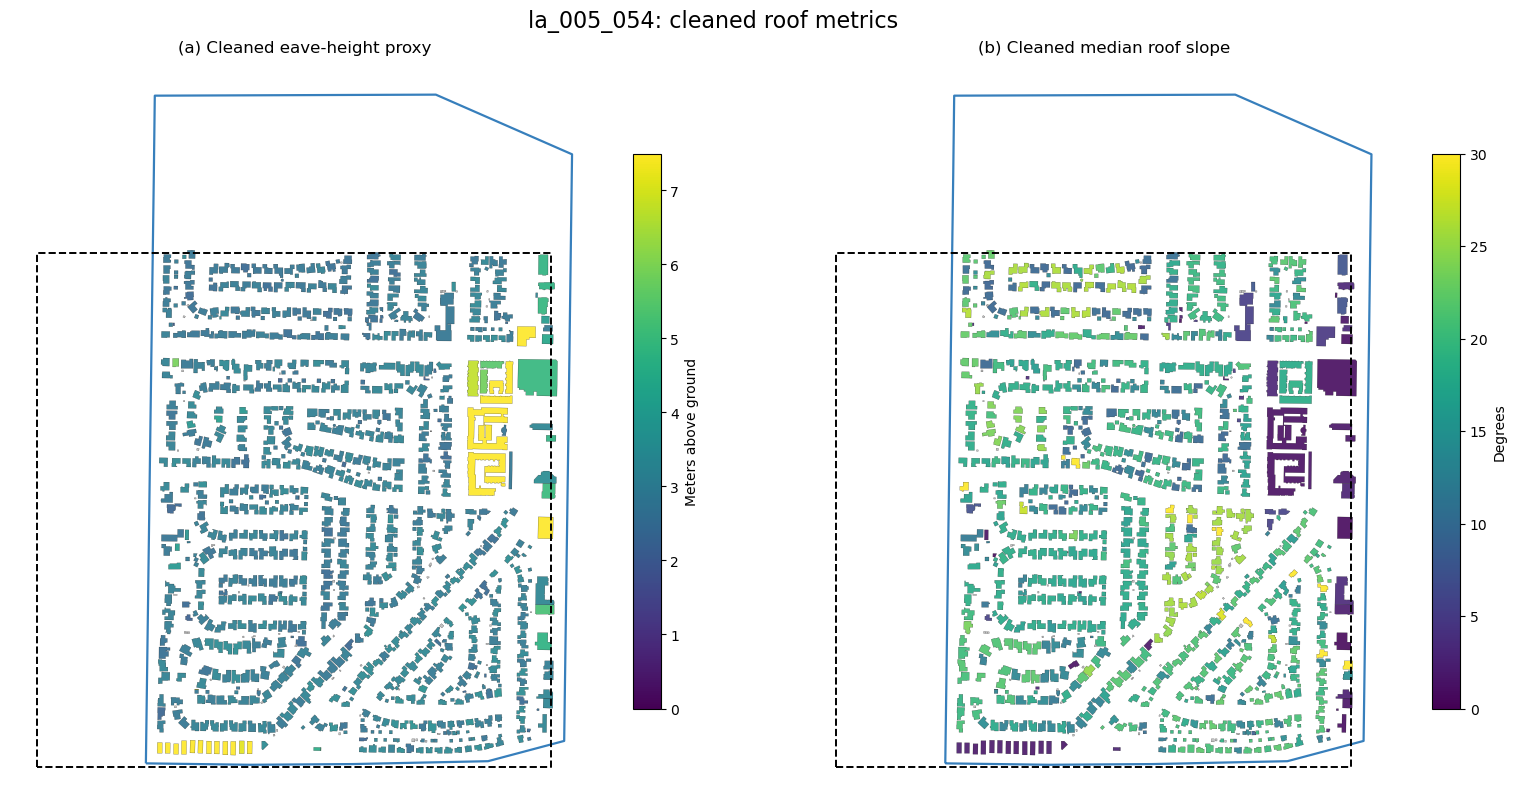

In [5]:
eave_field = 'clean_roof_height_p10_m'
slope_field = 'clean_slope_median_deg'
eave_vmax = comparison_map[eave_field].quantile(0.98)
eave_vmax = 1.0 if pd.isna(eave_vmax) or eave_vmax <= 0 else eave_vmax

fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)
map_specs = [
    (eave_field, '(a) Cleaned eave-height proxy', 'Meters above ground', 0, eave_vmax),
    (slope_field, '(b) Cleaned median roof slope', 'Degrees', 0, 30),
]
for ax, (field, title, label, vmin, vmax) in zip(axes, map_specs):
    comparison_map.plot(
        ax=ax, column=field, cmap='viridis', vmin=vmin, vmax=vmax,
        legend=True, legend_kwds={'label': label, 'shrink': 0.75},
        missing_kwds={'color': '#bdbdbd'},
        edgecolor='black', linewidth=0.15, alpha=0.9, zorder=2,
    )
    comparison_tracts.boundary.plot(
        ax=ax, color='#2171b5', linewidth=1.6, alpha=0.9, zorder=3,
    )
    comparison_core.boundary.plot(
        ax=ax, color='black', linewidth=1.4, linestyle='--', zorder=4,
    )
    ax.set_title(title)
    ax.set_aspect('equal')
    ax.set_axis_off()
fig.suptitle(f'{comparison_tile_id}: cleaned roof metrics', fontsize=16)
plt.show()

In [5]:
import pandas as pd

fp = '/Users/adamswietek/Documents/NDSC_HiddenHousing/data/03_processed/roof_slope_udu_ept_cleaned/udu_300_tracts_roof_classification.parquet'
data = pd.read_parquet(fp)

In [7]:
data

,AIN,BLD_ID,median_slope_clean_deg,lariac_height_m,roof_type_clean
0,2565017900,201700229930,1.454613,11.588496,flat
1,2565017900,475375914379,2.135838,3.688080,flat
2,2565017900,475530914656,1.191733,4.657344,flat
3,2565017900,475587914475,2.809513,3.264408,flat
4,2565017900,475594914535,22.993292,6.251448,pitched
...,...,...,...,...,...
281360,7440036907,475106721095,17.857765,9.643872,pitched
281361,7440036907,475196720835,17.727058,9.268968,pitched
281362,7440036907,475220720615,14.779127,2.694432,insufficient_points
281363,7440036907,475409720849,NaN,4.248912,insufficient_points
